# Analítica de Datos Proyecto Final

# Regresión Logística

Nombre: Juan Adrián García Guerra
    
Correo electrónico: juan.garcia8091@alumnos.udg.mx
        
Código de alumno: 304280911
    
Fecha: 4 de mayo de 2024
    
Usando el conjunto de datos siguiente:  https://www.kaggle.com/brllrb/uberand-lyft-dataset-boston-ma, construir  un modelo de regresión logística binario. El objetivo es encontrar patrones entre las solicitudes realizadas a Uber y Lyft. También se hará un análisis de los resultados usando como métricas: la exactitud (accuracy), la sensibilidad (recall) y la métrica F1 (Score F1). Regresión logistica: Solicitudes Uber & Lyft
        
# Contenido

1. Preparar los datos
2. Análisis exploratorio de datos
3. Visualizar los datos
4. Crear la matriz de atributos y el vector de etiquetas
5. Escalar los datos (para cada atributo)
6. Evaluar el error
7. Realizar la regresión
8. Comparar las predicciones

# Importamos Librerías

In [92]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Asignamos la ruta del dataset

In [93]:
PATH = "datasets"

# 1. Preparación de los datos

In [94]:
with zipfile.ZipFile(PATH + '/archivo.zip', 'r') as archive:
    # Extrae todo el contenido del archivo zip en el directorio actual
    archive.extractall(PATH)

In [95]:
os.listdir(PATH)

['.ipynb_checkpoints', 'archivo.zip', 'rideshare_kaggle.csv']

# Cargamos el dataset

In [96]:
Ask = pd.read_csv(PATH + '/rideshare_kaggle.csv')

In [97]:
Ask.head()

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,1.543554e+09,4,30,11,2018-11-30 04:53:02,America/New_York,Haymarket Square,North Station,Lyft,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,1.543463e+09,3,29,11,2018-11-29 03:49:20,America/New_York,Haymarket Square,North Station,Lyft,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


# 2. Análisis Exploratorio de Datos (EDA)

Descripción de los datos

In [98]:
Ask.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 57 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           693071 non-null  object 
 1   timestamp                    693071 non-null  float64
 2   hour                         693071 non-null  int64  
 3   day                          693071 non-null  int64  
 4   month                        693071 non-null  int64  
 5   datetime                     693071 non-null  object 
 6   timezone                     693071 non-null  object 
 7   source                       693071 non-null  object 
 8   destination                  693071 non-null  object 
 9   cab_type                     693071 non-null  object 
 10  product_id                   693071 non-null  object 
 11  name                         693071 non-null  object 
 12  price                        637976 non-null  float64
 13 

In [99]:
# Completamos los datos nulos de la columna price con la media
Ask.loc[:, 'price'].fillna(Ask['price'].mean(), inplace=True)

In [100]:
Ask['price'] = Ask['price'].fillna(Ask['price'].mean())

In [101]:
# Se depuran las columnas no requeridas
columns_to_drop = ['id', 'timestamp', 'datetime', 'timezone', 'product_id', 'latitude', 'longitude']
Ask.drop(columns=columns_to_drop, inplace=True)

In [102]:
Ask.describe()

,hour,day,month,price,distance,surge_multiplier,temperature,apparentTemperature,precipIntensity,precipProbability,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
count,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,...,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05
mean,11.619137,17.794365,11.586684,16.545125,2.189430,1.013870,39.584388,35.881222,0.008922,0.146076,...,0.037374,1.544044e+09,33.457774,1.544042e+09,45.261313,1.544047e+09,29.731002,1.544048e+09,41.997343,1.544048e+09
std,6.948114,9.982286,0.492429,8.946069,1.138937,0.091641,6.726084,7.918707,0.026901,0.328938,...,0.055214,6.912028e+05,6.467224,6.901954e+05,5.645046,6.901353e+05,7.110494,6.871862e+05,6.936841,6.910777e+05
min,0.000000,1.000000,11.000000,2.500000,0.020000,1.000000,18.910000,12.130000,0.000000,0.000000,...,0.000000,1.543162e+09,15.630000,1.543122e+09,33.510000,1.543154e+09,11.810000,1.543136e+09,28.950000,1.543187e+09
25%,6.000000,13.000000,11.000000,9.500000,1.280000,1.000000,36.450000,31.910000,0.000000,0.000000,...,0.000000,1.543421e+09,30.170000,1.543399e+09,42.570000,1.543439e+09,27.760000,1.543399e+09,36.570000,1.543439e+09
50%,12.000000,17.000000,12.000000,16.000000,2.160000,1.000000,40.490000,35.900000,0.000000,0.000000,...,0.000400,1.543770e+09,34.240000,1.543727e+09,44.680000,1.543788e+09,30.130000,1.543745e+09,40.950000,1.543788e+09
75%,18.000000,28.000000,12.000000,22.500000,2.920000,1.000000,43.580000,40.080000,0.000000,0.000000,...,0.091600,1.544807e+09,38.880000,1.544789e+09,46.910000,1.544814e+09,35.710000,1.544789e+09,44.120000,1.544818e+09
max,23.000000,30.000000,12.000000,97.500000,7.860000,3.000000,57.220000,57.220000,0.144700,1.000000,...,0.145900,1.545152e+09,43.100000,1.545192e+09,57.870000,1.545109e+09,40.050000,1.545134e+09,57.200000,1.545109e+09


In [103]:
Ask.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 50 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   hour                         693071 non-null  int64  
 1   day                          693071 non-null  int64  
 2   month                        693071 non-null  int64  
 3   source                       693071 non-null  object 
 4   destination                  693071 non-null  object 
 5   cab_type                     693071 non-null  object 
 6   name                         693071 non-null  object 
 7   price                        693071 non-null  float64
 8   distance                     693071 non-null  float64
 9   surge_multiplier             693071 non-null  float64
 10  temperature                  693071 non-null  float64
 11  apparentTemperature          693071 non-null  float64
 12  short_summary                693071 non-null  object 
 13 

In [104]:
from sklearn.preprocessing import LabelEncoder

# Se transforman los datos numéricos
columnas_no_numericas=['source', 'destination', 'cab_type', 'name', 'short_summary', 'long_summary', 'icon']

encoder = LabelEncoder()
for columna in columnas_no_numericas:
    Ask[columna] = encoder.fit_transform(Ask[columna])

In [105]:
# Se aplica la correlación
correlacion = Ask.corr()
correlacion

,hour,day,month,source,destination,cab_type,name,price,distance,surge_multiplier,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
hour,1.000000,0.066090,-0.079379,0.002685,-0.004190,-0.001257,0.000158,0.000538,0.002280,-0.000077,...,0.019940,-0.027518,0.015513,-0.027027,0.002958,-0.027990,0.015820,-0.027704,0.002897,-0.027785
day,0.066090,1.000000,-0.861306,-0.000760,-0.001813,0.001868,0.000993,-0.000693,-0.000627,0.001389,...,0.145568,-0.341198,0.038076,-0.333990,-0.304870,-0.344532,-0.019940,-0.335043,-0.444445,-0.344411
month,-0.079379,-0.861306,1.000000,0.000174,0.000670,-0.000776,-0.000106,0.000876,0.002298,-0.000628,...,-0.213054,0.770767,-0.191803,0.765255,0.105326,0.772989,-0.191153,0.766031,0.215076,0.772896
source,0.002685,-0.000760,0.000174,1.000000,-0.007584,0.000912,0.000335,-0.024336,-0.091369,-0.032521,...,0.000411,-0.000515,0.000545,-0.000349,0.000599,-0.000595,-0.000112,-0.000417,0.000514,-0.000573
destination,-0.004190,-0.001813,0.000670,-0.007584,1.000000,0.000835,0.000307,-0.044439,-0.147394,-0.001027,...,0.000536,-0.001222,-0.000603,-0.001170,0.000851,-0.001226,0.001010,-0.001163,0.002080,-0.001204
cab_type,-0.001257,0.001868,-0.000776,0.000912,0.000835,1.000000,0.366068,-0.080464,0.001924,-0.169522,...,-0.000241,0.000905,-0.001249,0.000940,-0.002849,0.000874,-0.002211,0.000902,-0.003340,0.000857
name,0.000158,0.000993,-0.000106,0.000335,0.000307,0.366068,1.000000,-0.572357,0.000705,-0.081516,...,-0.001628,0.001123,-0.001127,0.001119,-0.002061,0.001121,-0.001698,0.001066,-0.002416,0.001124
price,0.000538,-0.000693,0.000876,-0.024336,-0.044439,-0.080464,-0.572357,1.000000,0.330038,0.240220,...,0.001069,0.000732,-0.000411,0.000738,-0.000527,0.000735,-0.000556,0.000781,-0.000278,0.000716
distance,0.002280,-0.000627,0.002298,-0.091369,-0.147394,0.001924,0.000705,0.330038,1.000000,0.024769,...,0.000648,0.003562,-0.003396,0.003428,-0.004191,0.003580,-0.003937,0.003526,-0.004238,0.003584
surge_multiplier,-0.000077,0.001389,-0.000628,-0.032521,-0.001027,-0.169522,-0.081516,0.240220,0.024769,1.000000,...,-0.000101,0.000544,-0.000724,0.000554,-0.001951,0.000522,-0.001304,0.000464,-0.002154,0.000519


No tenemos datos faltantes. No se rellenan datos. Se determina que los datos que se encuentran en diferentes escalas, por lo tanto es necesario escalar los datos

# 3. Visualización de datos

In [106]:
import seaborn as sns 

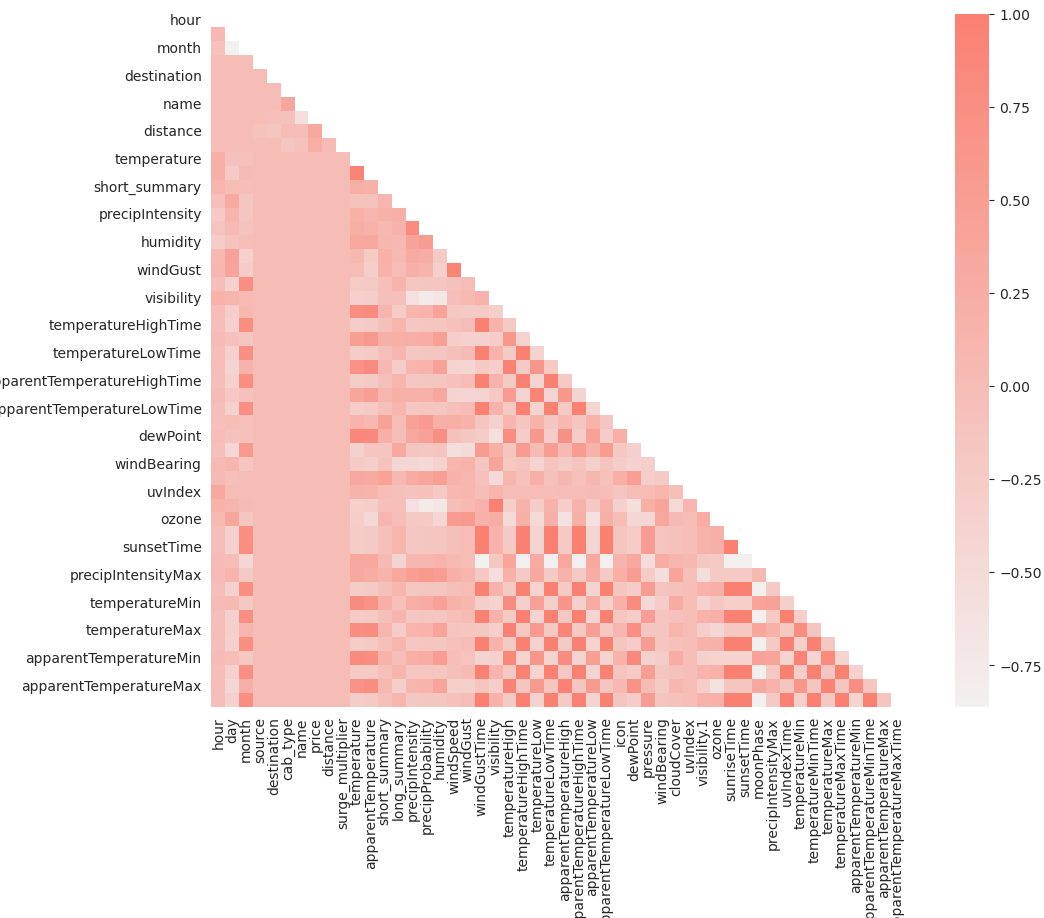

In [107]:
# Se visualiza la correlación
cores = sns.color_palette('light:salmon', as_cmap=True)
mask = np.zeros_like(correlacion)
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(13,9))
    ax = sns.heatmap(correlacion, cmap=cores, mask=mask, square=True,)

Text(0.5, 0, 'Precio')

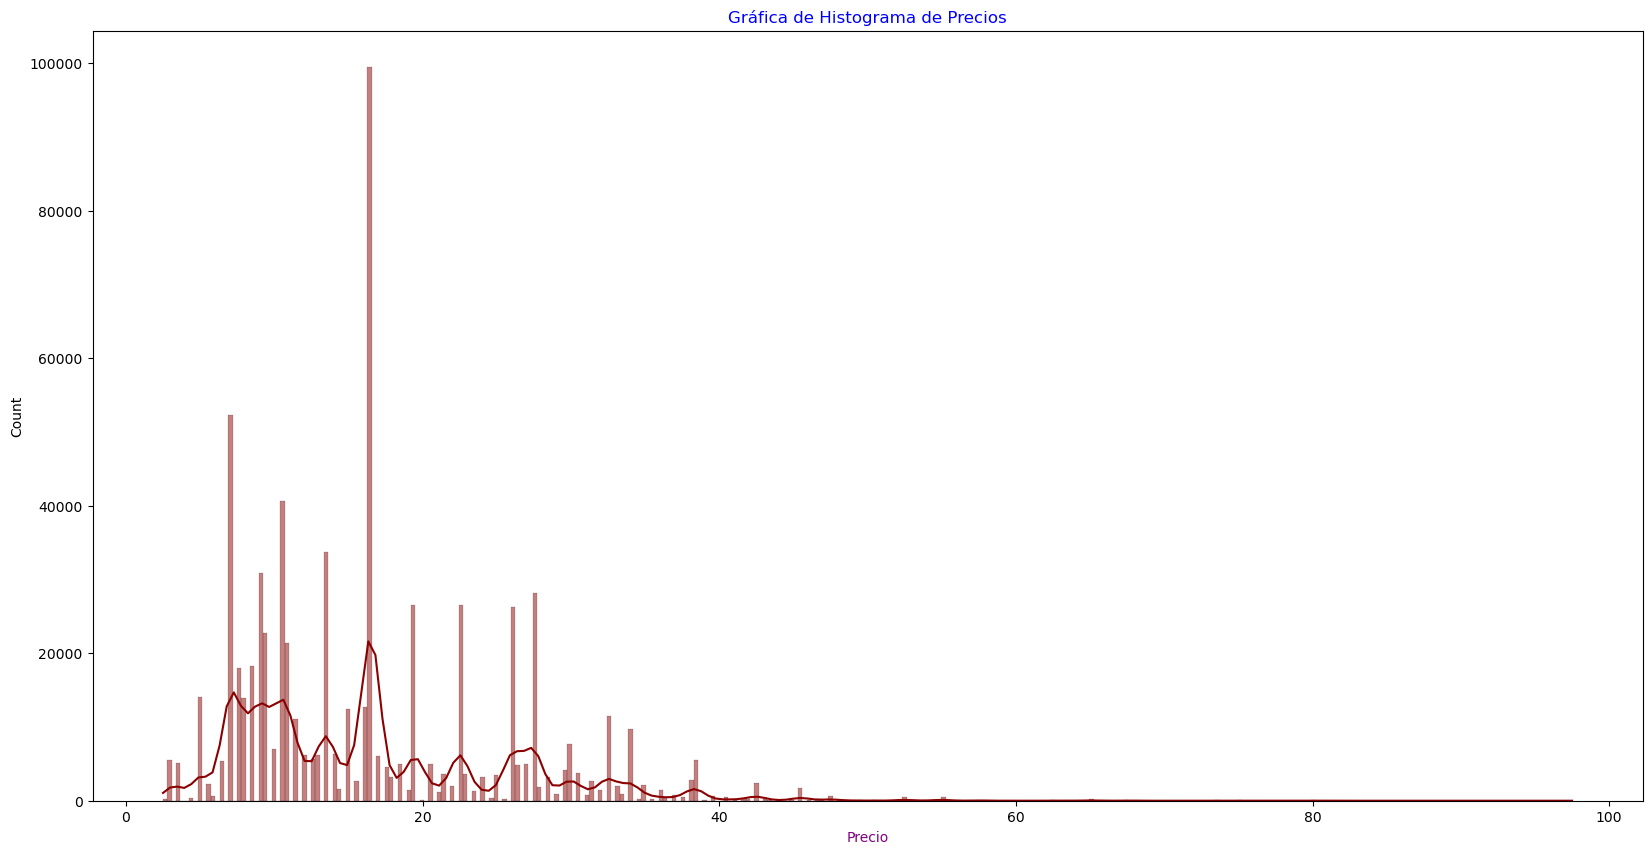

In [108]:
ax = sns.histplot(data=Ask, x='price', kde=True, color='darkred')
ax.figure.set_size_inches(20,10)
ax.set_title('Gráfica de Histograma de Precios', color='blue')
ax.set_xlabel('Precio', color='purple')

In [109]:
def grafica(data, colx, coly, color='brown'):
    plt.plot(data[colx], data[coly], 'o')
    plt.xlabel(colx, size=10, color='darkgreen')
    plt.ylabel(coly, size=10, color='darkred')
    plt.title(colx +' vs ' + coly, size=15)
    # plt.title('Tipo de Servicio contra la Distancia', size = 15, color='orange', fontweight='bold')
    plt.show()

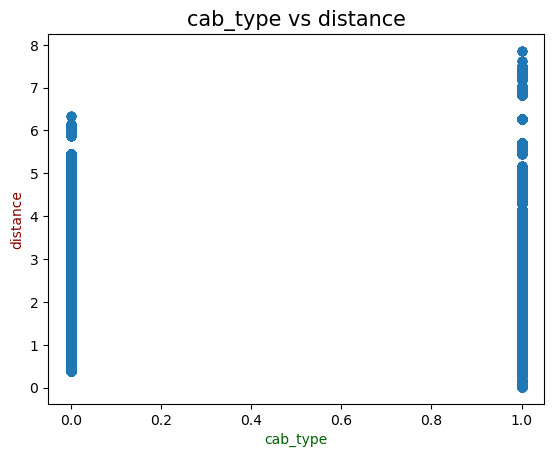

In [110]:
grafica(Ask, 'cab_type', 'distance', )

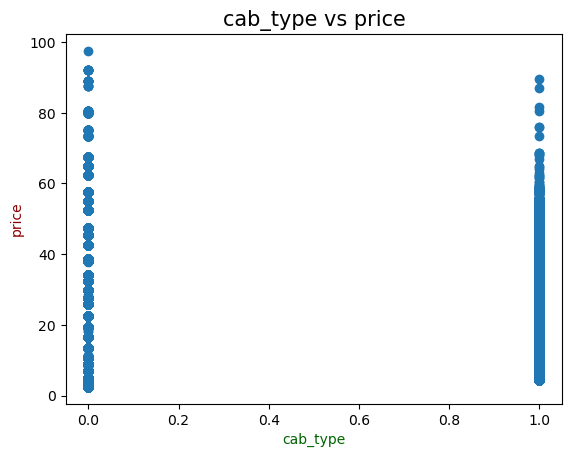

In [111]:
grafica(Ask, 'cab_type', 'price')

Text(0.5, 0, 'Distancia')

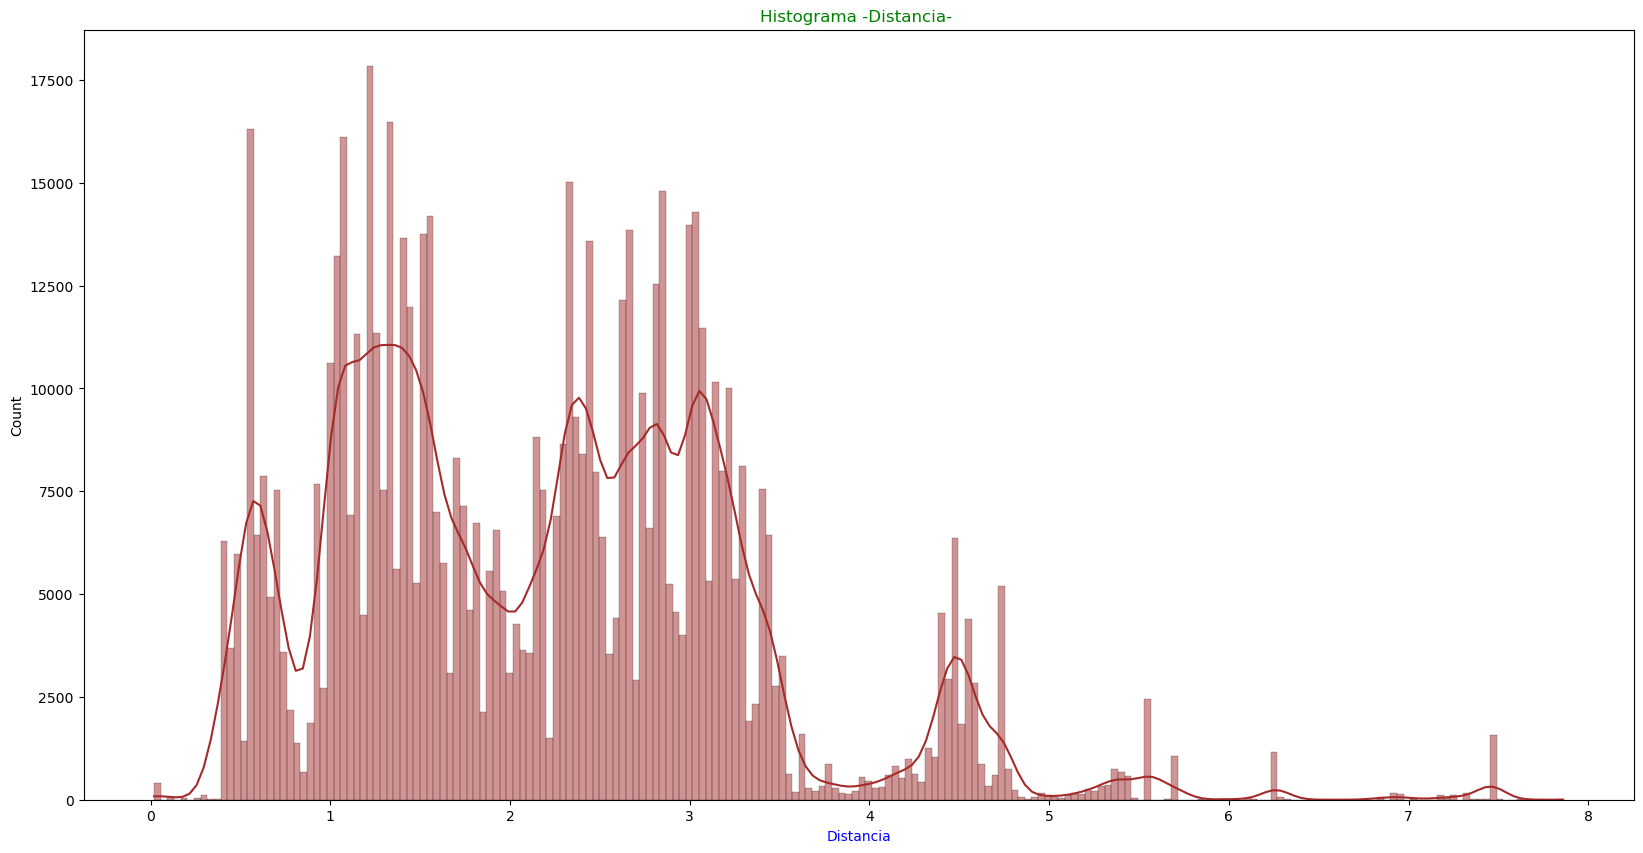

In [112]:
ax = sns.histplot(data=Ask, x='distance', kde=True, color='brown')
ax.figure.set_size_inches(20,10)
ax.set_title('Histograma -Distancia- ', color='green')
ax.set_xlabel('Distancia', color='blue')

Los datos se concentran en la primera mitad de las variables independientes

In [113]:
w = 0.005
b = 0.1

<function matplotlib.pyplot.show(close=None, block=None)>

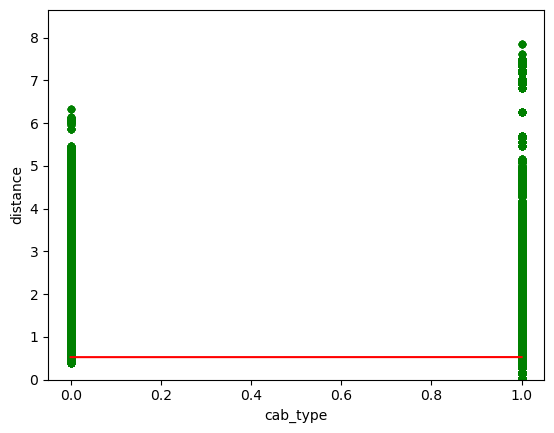

In [127]:
# Puntos de la recta
x = np.linspace(0,Ask['cab_type'].max(),100)
y = 1 / (1 + np.exp(-(w * x + b)))
# Gráfica de la recta
Ask.plot.scatter(x='cab_type', y='distance', c='green')
plt.plot(x,y,'-r')
plt.ylim(0,Ask['distance'].max()*1.1)

plt.show

# 4. Crear la matriz de atributos $X$ y el vector de etiquetas $y$

In [115]:
y = Ask['cab_type']
X = Ask.iloc[:, 1:]

In [116]:
X.head()

,day,month,source,destination,cab_type,name,price,distance,surge_multiplier,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,16,12,5,7,0,7,5.0,0.44,1.0,42.34,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,27,11,5,7,0,2,11.0,0.44,1.0,43.58,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,28,11,5,7,0,5,7.0,0.44,1.0,38.33,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,30,11,5,7,0,4,26.0,0.44,1.0,34.38,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,29,11,5,7,0,6,9.0,0.44,1.0,37.44,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


In [117]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: cab_type, dtype: int32

# 5.1 Escalado de los datos usando StandardScaler

StandardScaler calcula y resta la media de las muestras, para luego escalar la varianza de la unidad. La puntuación estándar (Z-Score) de una muestra $x$ se calcula como $z = \frac{x - \mu}{s}$ donde $\mu$ es la media de las muestras de entrenamiento o 0, si with_mean=False; y $s$ es la desviación estándar de las muestras de entrenamiento o 1, si with_std=False  

In [118]:
sc = StandardScaler()
ss_data = sc.fit_transform(X.values) # fit_transform recibe y regresa un ndarray
Xsc = pd.DataFrame(data=ss_data, columns=X.columns)

In [119]:
Xsc.describe()

,day,month,source,destination,cab_type,name,price,distance,surge_multiplier,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
count,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,...,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05,6.930710e+05
mean,-5.163500e-15,2.777002e-14,-3.688579e-15,3.895420e-15,4.205163e-14,-1.094983e-15,1.851081e-15,1.605019e-15,-4.076322e-14,-1.631159e-16,...,1.308501e-15,6.000910e-14,-3.302525e-16,7.301407e-14,2.631438e-15,1.096761e-13,-2.102476e-15,-2.828620e-14,4.031099e-15,-3.731731e-14
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-1.682418e+00,-1.191411e+00,-1.593327e+00,-1.593380e+00,-1.120073e+00,-1.600311e+00,-1.569978e+00,-1.904786e+00,-1.513489e-01,-3.073765e+00,...,-6.769040e-01,-1.276567e+00,-2.756637e+00,-1.332391e+00,-2.081705e+00,-1.293805e+00,-2.520361e+00,-1.326621e+00,-1.880878e+00,-1.246162e+00
25%,-4.802876e-01,-1.191411e+00,-7.237682e-01,-7.238051e-01,-1.120073e+00,-8.067826e-01,-7.875113e-01,-7.984905e-01,-1.513489e-01,-4.660053e-01,...,-6.769040e-01,-9.015686e-01,-5.083753e-01,-9.307654e-01,-4.767570e-01,-8.817118e-01,-2.771964e-01,-9.441913e-01,-7.823946e-01,-8.815137e-01
50%,-7.957747e-02,8.393412e-01,-1.440622e-01,-1.440887e-01,8.927988e-01,-1.325389e-02,-6.093468e-02,-2.583969e-02,-1.513489e-01,1.346418e-01,...,-6.696595e-01,-3.963619e-01,1.209524e-01,-4.561169e-01,-1.029776e-01,-3.757237e-01,5.611406e-02,-4.412704e-01,-1.509828e-01,-3.762155e-01
75%,1.022375e+00,8.393412e-01,7.254967e-01,7.254859e-01,8.927988e-01,7.802749e-01,6.656419e-01,6.414497e-01,-1.513489e-01,5.940476e-01,...,9.821031e-01,1.103633e+00,8.384168e-01,1.082579e+00,2.920593e-01,1.110942e+00,8.408702e-01,1.077970e+00,3.059979e-01,1.113633e+00
max,1.222730e+00,8.393412e-01,1.595056e+00,1.595060e+00,8.927988e-01,1.573804e+00,9.049218e+00,4.978831e+00,2.167290e+01,2.621975e+00,...,1.965554e+00,1.603632e+00,1.490938e+00,1.666762e+00,2.233586e+00,1.538685e+00,1.451236e+00,1.580890e+00,2.191584e+00,1.535583e+00


# 5.2 Escalado de los datos usando MinMaxScaler

In [120]:
scaler = MinMaxScaler()
norm_data = scaler.fit_transform(X.values)
Xnorm = pd.DataFrame(data=norm_data, columns=X.columns)

In [121]:
Xnorm.head()

,day,month,source,destination,cab_type,name,price,distance,surge_multiplier,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,0.517241,1.0,0.454545,0.636364,0.0,0.583333,0.026316,0.053571,0.0,0.611590,...,0.874572,0.913201,0.883145,0.913043,0.417488,0.928177,0.776204,0.938739,0.322832,0.921348
1,0.896552,0.0,0.454545,0.636364,0.0,0.166667,0.089474,0.053571,0.0,0.643957,...,0.891021,0.045208,0.904987,0.053913,0.566092,0.049724,0.863669,0.077477,0.529912,0.033708
2,0.931034,0.0,0.454545,0.636364,0.0,0.416667,0.047368,0.053571,0.0,0.506917,...,0.729267,0.088608,0.718238,0.123478,0.576355,0.084715,0.680949,0.120721,0.536991,0.069288
3,1.000000,0.0,0.454545,0.636364,0.0,0.333333,0.247368,0.053571,0.0,0.403811,...,0.000000,0.173599,0.693120,0.206957,0.472906,0.182320,0.654745,0.207207,0.339115,0.168539
4,0.965517,0.0,0.454545,0.636364,0.0,0.500000,0.068421,0.053571,0.0,0.483686,...,0.000685,0.130199,0.635967,0.135652,0.355911,0.136280,0.612606,0.127928,0.240708,0.121723


In [122]:
Xnorm.describe()

,day,month,source,destination,cab_type,name,price,distance,surge_multiplier,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
count,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,...,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000
mean,0.579116,0.586684,0.499729,0.499736,0.556455,0.504176,0.147843,0.276713,0.006935,0.539660,...,0.256165,0.443222,0.648991,0.444256,0.482402,0.456773,0.634596,0.456274,0.461853,0.447979
std,0.344217,0.492429,0.313639,0.313633,0.496803,0.315049,0.094169,0.145273,0.045821,0.175570,...,0.378436,0.347198,0.235429,0.333428,0.231734,0.353047,0.251788,0.343937,0.245552,0.359487
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.413793,0.000000,0.272727,0.272727,0.000000,0.250000,0.073684,0.160714,0.000000,0.457844,...,0.000000,0.130199,0.529305,0.133913,0.371921,0.145488,0.564802,0.131532,0.269735,0.131086
50%,0.551724,1.000000,0.454545,0.454545,1.000000,0.500000,0.142105,0.272959,0.000000,0.563299,...,0.002742,0.305606,0.677466,0.292174,0.458539,0.324125,0.648725,0.304505,0.424779,0.312734
75%,0.931034,1.000000,0.727273,0.727273,1.000000,0.750000,0.210526,0.369898,0.000000,0.643957,...,0.627827,0.826401,0.846378,0.805217,0.550082,0.848987,0.846317,0.827027,0.536991,0.848315
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# 6. Entrenamiento y evaluación del modelo de regresión logística

In [123]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

def regression(X, y):
    # Escalar los datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Dividir los datos en el conjunto de entrenamiento y el de prueba
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, shuffle=True)
    
    # Construir el modelo
    model = LogisticRegression()
    model.fit(X_train, y_train)
    
    # Realizar las predicciones
    y_pred = model.predict(X_test)
    
    # Evaluar el modelo
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Mostrar los resultados
    print("Accuracy:", accuracy)
    print("Confusion Matrix:")
    print(conf_matrix)
    print("Precision:", precision)
    print("Recall (Sensibilidad):", recall)
    print("F1 Score:", f1)
    
    return y_test, y_pred

# Llamar a la función regresión con datos X e y
y_test, y_pred = regression(X, y)

Accuracy: 1.0
Confusion Matrix:
[[ 92130      0]
 [     0 115792]]
Precision: 1.0
Recall (Sensibilidad): 1.0
F1 Score: 1.0


# 7.1 Probar la regresión con los datos estandarizados (StandardScaler)

In [124]:
y_test_sc, y_sc = regression(Xsc, y)
plt.show()

Accuracy: 1.0
Confusion Matrix:
[[ 92324      0]
 [     0 115598]]
Precision: 1.0
Recall (Sensibilidad): 1.0
F1 Score: 1.0


# 7.2 Probar la regresión con los datos normalizados (MinMaxScaler) 

In [125]:
y_test_norm, y_norm = regression(Xnorm, y)

Accuracy: 1.0
Confusion Matrix:
[[ 92286      0]
 [     0 115636]]
Precision: 1.0
Recall (Sensibilidad): 1.0
F1 Score: 1.0


# Conclusión

Accuracy (Precisión): Significa que el porcentaje de predicciones correctas de todas las predicciones realizadas es del 100%. Todas las muestras en el conjunto de prueba se clasificaron correctamente.

Confusion Matrix: Muestra que no hubo falsos positivos en el conjunto de prueba. Todos los datos negativos fueron correctamente identificados como negativos, y todos los datos positivos fueron correctamente identificados como positivos.

Recall: Significa que el porcentaje de muestras positivas que fueron correctamente identificadas por el modelo es del 100%. No hubo falsos negativos en las predicciones

F1 Score: El puntaje de F1 indica que no hubo errores ni falsos positivos ni falsos negativos en las predicciones